# Dokumentacja projektu

Uzupełniaj sekcje w zadaniach podanych w nawiasach. Zastępuj teksty w nawiasach kwadratowych.

## Informacje ogólne

* Tytuł: Klasyfikacja egipskich hieroglifów przy użyciu konwolucyjnych sieci neuronowych
* Autor: Amelia Dolińska
* Modalność: Obraz
* Problem klasyfikacji: 95 klas znaków hieroglificznych. Klasami są nazwy opisowe egipskich hieroglifów.

## Problem i pytanie eksperymentalne (Zadanie 1)

Celem eksperymentu jest zbadanie, jak zastosowanie fine-tuningu modelu pretrained wpływa na skuteczność wieloklasowej klasyfikacji egipskich hieroglifów. Porównane zostaną trzy podejścia: model pretrained z zamrożonym ekstraktorem cech, ten sam model poddany fine-tuningowi oraz prosta sieć CNN trenowana od podstaw. Pozwoli to ocenić, czy dostosowanie wstępnie wytrenowanych wag do badanego zbioru poprawia wyniki względem wykorzystania zamrożonych cech i uczenia od podstaw.

## Dane i licencja (Zadanie 1)

* **Źródło danych:** https://www.kaggle.com/datasets/alexandrepetit881234/egyptian-hieroglyphs/data
* **Licencja danych:** CC BY 4.0 (Attribution 4.0 International), zgodnie z informacją na Kaggle. Pierwotny zbiór został opublikowany w Roboflow Universe przez niezindetyfikowango użytkownika.
* **Sposób pobierania:** Za pomocą biblioteki `kagglehub`, zostało to opisane w notebooku Zadania 1.
* **Liczba przykładów:** 3890
* **Liczba klas:** '100', 'Among', 'Angry', 'Ankh', 'Aroura', 'At', 'Bad_Thinking', 'Bandage', 'Bee', 'Belongs', 'Birth', 'Board_Game', 'Book', 'Boy', 'Branch', 'Bread', 'Brewer', 'Builder', 'Bury', 'Canal', 'Cloth_on_Pole', 'Cobra', 'Composite_Bow', 'Cooked', 'Corpse', 'Dessert', 'Divide', 'Duck', 'Elephant', 'Enclosed_Mound', 'Eye', 'Fabric', 'Face', 'Falcon', 'Fingre', 'Fish', 'Flail', 'Folded_Cloth', 'Foot', 'Galena', 'Giraffe', 'He', 'Her', 'Hit', 'Horn', 'King', 'Leg', 'Length_Of_a_Human_Arm', 'Life_Spirit', 'Limit', 'Lion', 'Lizard', 'Loaf', 'Loaf_Of_Bread', 'Man', 'Mascot', 'Meet', 'Mother', 'Mouth', 'Musical_Instrument', 'Nile_Fish', 'Not', 'Now', 'Nurse', 'Nursing', 'Occur', 'One', 'Owl', 'Pair', 'Papyrus_Scroll', 'Pool', 'QuailChick', 'Reed', 'Ring', 'Rope', 'Ruler', 'Sail', 'Sandal', 'Semen', 'Small_Ring', 'Snake', 'Soldier', 'Star', 'Stick', 'Swallow', 'This', 'To_Be_Dead', 'To_Protect', 'To_Say', 'Turtle', 'Viper', 'Wall', 'Water', 'Woman', 'You'.
* **Potencjalne źródła wycieku danych:** Występowanie identycznych w różnych podzbiorach. Przeprowadzono kontrolę nazw plików oraz hashy, nie wykrywając duplikatów identycznych bajt po bajcie ani powtarzających się nazw. Kontrola ta nie wyklucza jednak występowania obrazów wizualnie podobnych.
* **Znane Ograniczenia:** Brak klasy 'Mascot' w zbiorze testowym przygotowanym przez autora danych, co uniemożliwia ocenę skuteczności modelu dla tej klasy na podstawie tego podzbioru.

## Protokół (Zadanie 1)

* **Jednostka generalizacji:** Obrazy symboli
* **Podział:** Zastsowano podział przygotwany wcześniej przez autora danych, w którym proporcje podziału wynoszą 70/20/10. Dystrybucja klas pomiędzy podzbiorami została opisane w notebooku Zadania 1. Podczas przeprowadzonego audytu danych nie zostały wykryte istotne nieprawidłowości w istniejącym podziale danych. Jedyne ograniczenie zostało opisane w sekcji wyżej.
* **Metryka główna i pomocnicze:** Metryka głównąbędzie macro F1-score, ponieważ klasy mają różną liczebność w poszczególnych podzbiorach, a uśrednianie makro nadaje każdej klasie jednakową wagę. F1-score uwzględnia zarówno precision, jak i recall, zapewniając zrównoważoną ocenę skuteczności klasyfikacji różnych hieroglifów, zamiast skupiać się wyłącznie na odsetku poprawnych predykcji. Metryki pomocnicze: accuracy, macro precision i macro recall, które uzupełnią ocenę modelu o ogólną skuteczność klasyfikacji oraz szczegółowe informacje o poprawności i kompletności rozpoznawania klas.
* **Seed:** 42. Zostanie wykorzystany do kontrolowania losowości, w tym inicjalizacji wag oraz kolejności próbek podczas treningu.
* **Final test:** zamrożony w commicie z tagiem `task-1`, identyfikatory w `splits/`. Jeśli podział był później poprawiany, podaj commit poprawionej wersji i opisz zmianę w dzienniku zmian.

| Zbiór | Liczba przykładów | Liczba niezależnych jednostek |
|---|---|---|
| train |2723|95|
| validation |778|95|
| final test |389|94|

## Wyniki (Zadania 2 do 5)

Wyniki na validation:

| Podejście | Zadanie | Metryka główna | Metryki pomocnicze | Czas i sprzęt | Uwagi |
|---|---|---|---|---|---|
| Trivial baseline | 2 | | | | |
| Baseline | 2 | | | | |
| Podejście pretrained | 3 | | | | |
| Rozszerzenie | 4 | | | | |

Wynik na final test, wyłącznie dla finalnego systemu i dopiero po utworzeniu tagu `final-freeze`:

| System | Metryka główna | Metryki pomocnicze |
|---|---|---|
| [nazwa z `final_system.md`] | | |

## Finalny system (Zadanie 5)

Pełny zapis jest w `final_system.md`. [Krótkie uzasadnienie wyboru na podstawie validation.]

## Reprodukcja

- **Wersja Pythona:** Python 3.13.16.
- **Instalacja środowiska:** instalacja wymaganych bibliotek na podstawie pliku `requirements.txt`.
- **Pobranie danych:** zbiór danych jest pobierany z Kaggle za pomocą biblioteki `kagglehub`:

```python
import kagglehub

path = kagglehub.dataset_download(
    "alexandrepetit881234/egyptian-hieroglyphs"
)
print("Path to dataset files:", path)
```

- **Kolejność uruchamiania:** Kod do Zadania 1 znajduje się w całości w notebooku `notebooks/01_data_and_protocol.ipynb`.
- **Sprzęt:** Google Colab (Zadanie 1 - CPU)
- **Przybliżony czas wykonania:** Zadanie 1 - około 10 sekund, bez uwzględnienia ewentualnego czasu pobierania danych.

## Ograniczenia

* **Ograniczenia danych:** Brak klasy 'Mascot' w zbiorze testowym przygotowanym przez autora danych, co uniemożliwia ocenę skuteczności modelu dla tej klasy na podstawie tego podzbioru.

## Dziennik zmian

| Data | Zadanie | Co zmieniono i dlaczego |
|---|---|---|
| 17.10.2026 | Zadanie 1 | Dodanie pliku oraz aktualizacja README.md |

## Licencja projektu

Kod źródłowy projektu jest udostępniony na licencji MIT. Zbiór danych wykorzystywany jest zgodnie z warunkami licencji CC BY 4.0 wskazanej na stronie Kaggle.

In [1]:
!python -V

Python 3.13.16


# Instalacja i Zaimportowanie Bibliotek

In [2]:
# req.txt

In [3]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import kagglehub
from pathlib import Path
from collections import defaultdict
import hashlib
import random
import matplotlib.image as mpimg
from PIL import Image

# Przygotowanie notebooka

In [4]:
SEED = 42

# Python
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch — CPU i GPU
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Bardziej powtarzalne operacje na GPU
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [5]:
# konfiguracja urządzenia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Pobieranie Danych

In [6]:
path = kagglehub.dataset_download("alexandrepetit881234/egyptian-hieroglyphs")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'egyptian-hieroglyphs' dataset.
Path to dataset files: /kaggle/input/egyptian-hieroglyphs


In [7]:
df_train = pd.read_csv(path + '/train/_annotations.csv')
df_val = pd.read_csv(path +'/valid/_annotations.csv')
df_test = pd.read_csv(path + '/test/_annotations.csv')

In [8]:
df_train.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,nile-fish-7-_jpg.rf.31e4278980878c47a1e6a2f8dd...,640,640,Nile_Fish,375,319,512,454
1,Her-8-_jpg.rf.32bcf63f4ae4d6aea53cea5b9c0059b4...,640,640,Her,211,247,368,339
2,composite_bow-34-_jpg.rf.33153e63f7158777c50d4...,640,640,Composite_Bow,158,183,336,282
3,snake-6-_jpg.rf.32ac52ece4bcc06b1ead936693df17...,640,640,Snake,181,351,318,506
4,king-26-_jpg.rf.329a5a8e366f4fe2e3a3dca88524cc...,640,640,King,218,290,339,524


In [9]:
data_dirs = {
    "train": path + '/train',
    "validation": path + '/valid',
    "test": path + '/test',
}

In [10]:
datasets = {
    "train": (df_train, Path(data_dirs['train'])),
    "validation": (df_val, Path(data_dirs['validation'])),
    "test": (df_test, Path(data_dirs['test'])),
}

In [11]:
image_extensions = {".jpg", ".jpeg", ".png"}

for split, (df, folder) in datasets.items():
    print(f"\n{'=' * 50}\n{split.upper()}\n{'=' * 50}")

    # Nazwy z CSV
    csv_names = df["filename"].astype(str).str.strip()
    csv_names_set = set(csv_names)

    # Pliki obrazów faktycznie znajdujące się w folderze
    folder_names_set = {
        p.name for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    }

    # 1. Pliki z CSV, których nie ma w folderze
    missing_files = sorted(csv_names_set - folder_names_set)

    # 2. Obrazy w folderze, których nie ma w CSV
    unannotated_files = sorted(folder_names_set - csv_names_set)

    # 3. Powtarzające się nazwy w CSV
    duplicate_rows = df[csv_names.duplicated(keep=False)]

    print(f"Liczba wierszy w CSV: {len(df)}")
    print(f"Liczba unikalnych nazw w CSV: {len(csv_names_set)}")
    print(f"Liczba obrazów w folderze: {len(folder_names_set)}")
    print(f"Pliki z CSV nieistniejące w folderze: {len(missing_files)}")
    print(f"Obrazy bez wpisu w CSV: {len(unannotated_files)}")
    print(f"Wiersze z powtarzającą się nazwą: {len(duplicate_rows)}")

    if missing_files:
        print("\nPliki z CSV, których nie znaleziono:")
        print(*missing_files[:20], sep="\n")

    if unannotated_files:
        print("\nObrazy bez anotacji w CSV:")
        print(*unannotated_files[:20], sep="\n")

    if not duplicate_rows.empty:
        print("\nPowtarzające się wpisy w CSV:")
        print(duplicate_rows.sort_values("filename"))


TRAIN
Liczba wierszy w CSV: 2723
Liczba unikalnych nazw w CSV: 2723
Liczba obrazów w folderze: 2723
Pliki z CSV nieistniejące w folderze: 0
Obrazy bez wpisu w CSV: 0
Wiersze z powtarzającą się nazwą: 0

VALIDATION
Liczba wierszy w CSV: 778
Liczba unikalnych nazw w CSV: 778
Liczba obrazów w folderze: 778
Pliki z CSV nieistniejące w folderze: 0
Obrazy bez wpisu w CSV: 0
Wiersze z powtarzającą się nazwą: 0

TEST
Liczba wierszy w CSV: 389
Liczba unikalnych nazw w CSV: 389
Liczba obrazów w folderze: 389
Pliki z CSV nieistniejące w folderze: 0
Obrazy bez wpisu w CSV: 0
Wiersze z powtarzającą się nazwą: 0


In [12]:
total = len(df_train) + len(df_val) + len(df_test)

print('Proporcja danych treningowych:', len(df_train)/total * 100)
print('Proporcja danych walidacyjnych:',len(df_val)/total * 100)
print('Proporcja danych testowych:',len(df_test)/total * 100)

Proporcja danych treningowych: 70.0
Proporcja danych walidacyjnych: 20.0
Proporcja danych testowych: 10.0


Podział wstępnie dokonany przez autora danych: 70/20/10. Jeżeli audyt danych nie wykaże żadnych problemów albo potencjalnych wycieków - możemy z niego skorzystać.

In [13]:
classes_train = set(df_train["class"].unique())
classes_val = set(df_val["class"].unique())
classes_test = set(df_test["class"].unique())

print("train:", len(classes_train))
print("val:", len(classes_val))
print("test:", len(classes_test))

train: 95
val: 95
test: 94


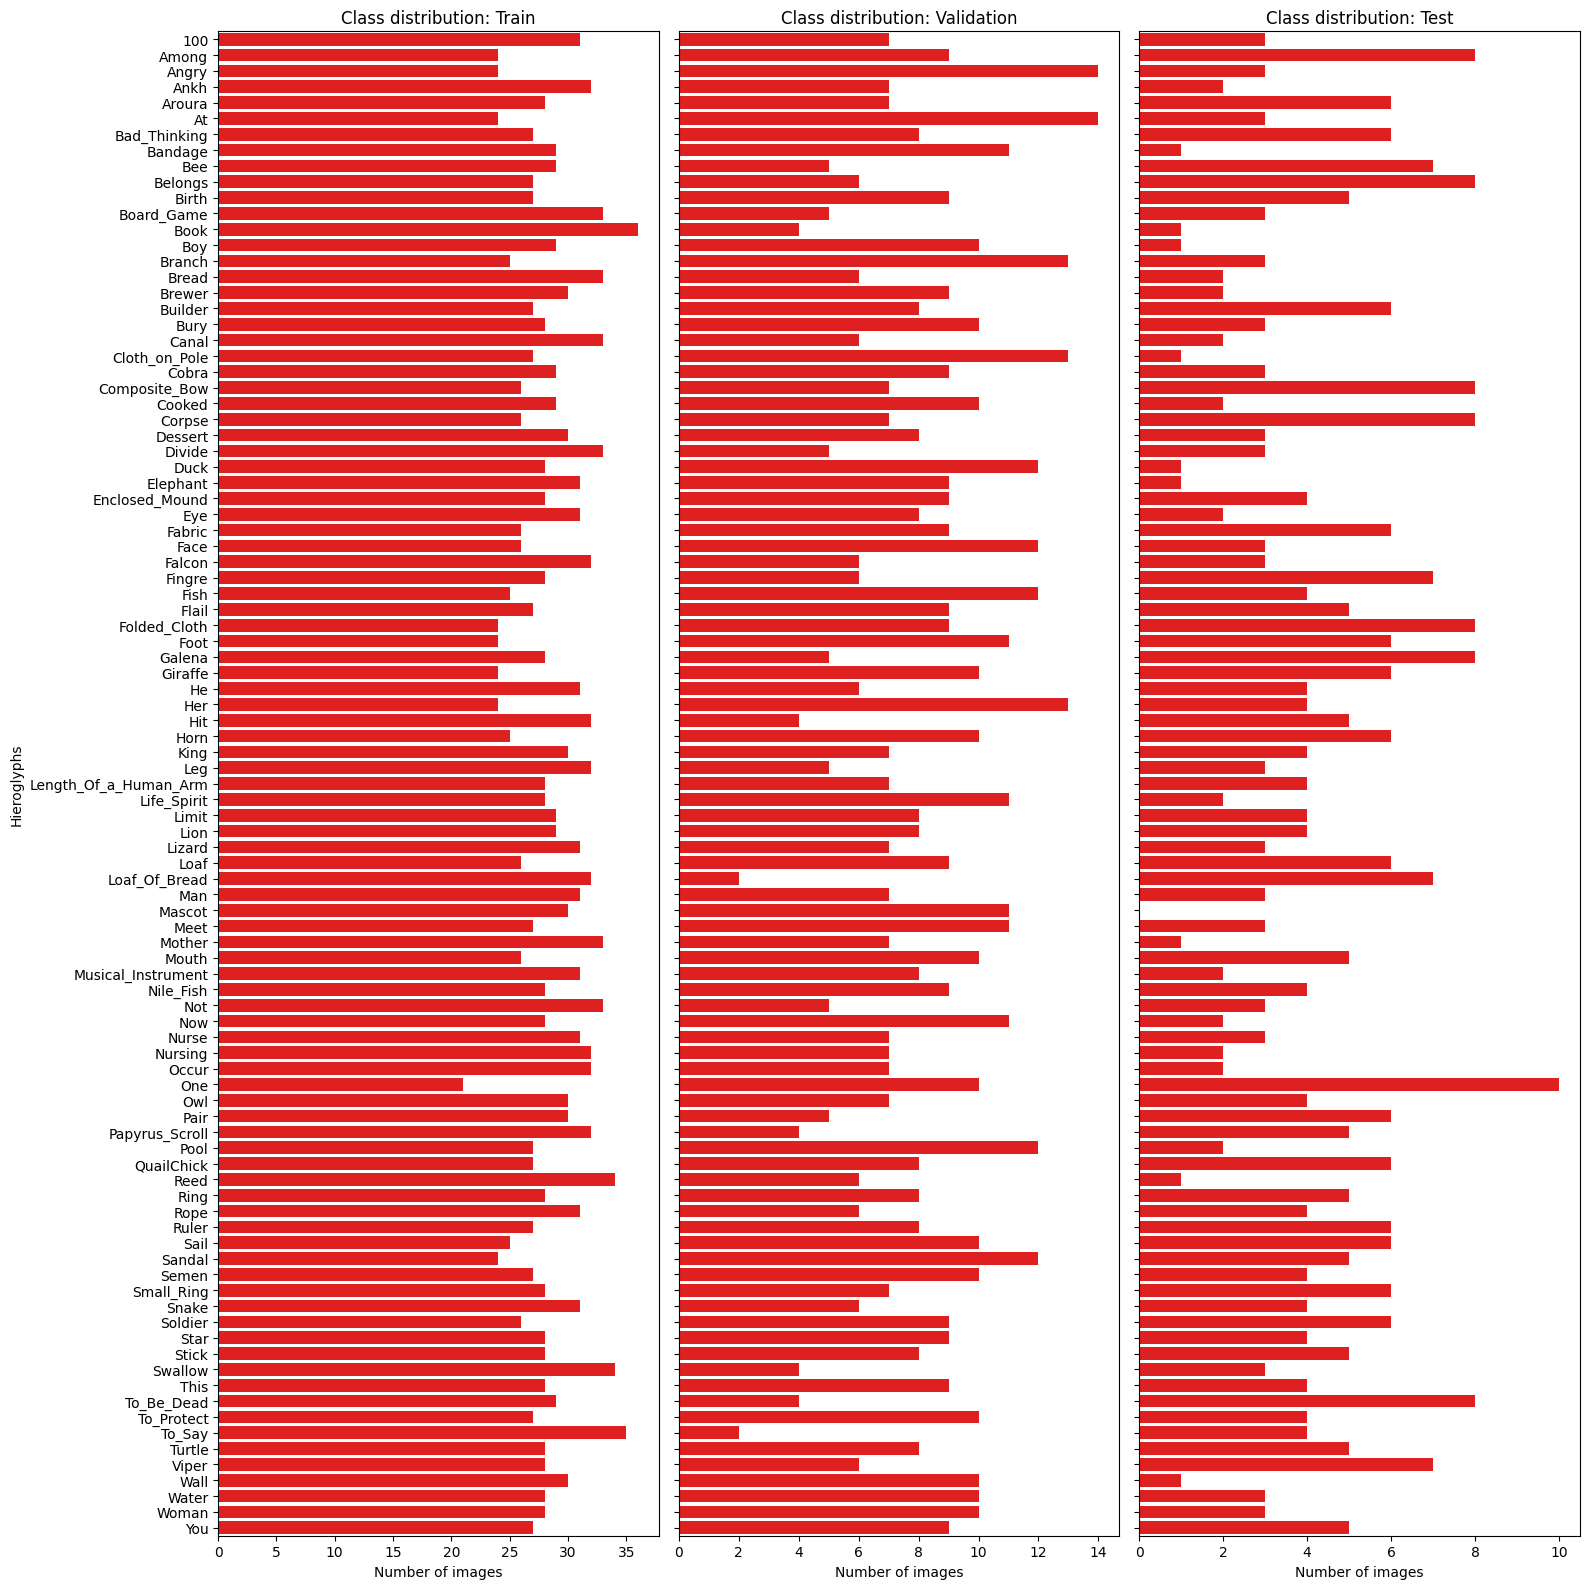

In [14]:
# Liczba obrazów przypadających na każdą klasę
category_counts = pd.DataFrame({
    "Train": df_train["class"].value_counts(),
    "Validation": df_val["class"].value_counts(),
    "Test": df_test["class"].value_counts()
}).fillna(0).astype(int)

# Sortowanie nazw klas alfabetycznie
category_counts = category_counts.sort_index()

# Wykresy
fig, axes = plt.subplots(1, 3, figsize=(16, 16), sharey=True)

for ax, split in zip(axes, ["Train", "Validation", "Test"]):
    sns.barplot(
        x=category_counts[split],
        y=category_counts.index,
        orient="h",
        color="red",
        ax=ax
    )

    ax.set_xlabel("Number of images")
    ax.set_ylabel("Hieroglyphs")
    ax.set_title(f"Class distribution: {split}")

plt.tight_layout()
plt.show()

In [15]:
category_counts['Total']= category_counts.sum(axis=1)
category_counts.head(5)

,Train,Validation,Test,Total
class,,,,
100,31,7,3,41
Among,24,9,8,41
Angry,24,14,3,41
Ankh,32,7,2,41
Aroura,28,7,6,41


In [16]:
missing_classes = classes_train - classes_test
print("Brakujące klasy w test:", missing_classes)

Brakujące klasy w test: {'Mascot'}


In [17]:
records = []

for split, data_dir in data_dirs.items():
    for filename in {
        str(f) for f in (
            Path(data_dir) / name
            for name in (
                df_train["filename"] if split == "train"
                else df_val["filename"] if split == "validation"
                else df_test["filename"]
            )
        )
    }:
        path = Path(filename)

        if not path.exists():
            continue

        with path.open("rb") as f:
            file_hash = hashlib.sha256(f.read()).hexdigest()

        records.append({
            "split": split,
            "filename": path.name,
            "path": str(path),
            "hash": file_hash,
        })

df_hashes = pd.DataFrame(records)

# Pliki o tym samym hashu są identyczne bajt po bajcie
duplicates = df_hashes[
    df_hashes.duplicated("hash", keep=False)
].sort_values(["hash", "split", "filename"])

print("Liczba plików uczestniczących w duplikatach:", len(duplicates))
print("Liczba grup identycznych plików:", duplicates["hash"].nunique())

if len(duplicates) > 0:
  print(duplicates[["split", "filename", "hash"]])

Liczba plików uczestniczących w duplikatach: 0
Liczba grup identycznych plików: 0


Ze względu na specyfikę zbioru danych obrazy należące do tej samej klasy wykazują podobieństwo wizualne (nie jest to ograniczeniem). W przeprowadzonej kontroli nie wykryto duplikatów identycznych bajt po bajcie na podstawie hashy ani powtarzających się nazw plików.

Rozkład liczebności klas pomiędzy podzbiorami oraz proporcje podziału 70/20/10 nie wskazują na oczywiste nieprawidłowości i są zgodne z możliwością zastosowania losowego podziału danych.

W związku z brakiem istotnych nieprawidłowości wykrytych w przeprowadzonym audycie danych, wykorzystany zostanie podział danych przygotowany przez autora zbioru. Jedynym zidentyfikowanym ograniczeniem jest brak klasy `Mascot` w zbiorze testowym, co uniemożliwia ocenę skuteczności modelu dla tej klasy na podstawie tego podzbioru. Nie wyklucza to jednak przeprowadzenia porównania modeli ani oceny ich zdolności do generalizacji w zakresie pozostałych 94 klas.

In [18]:
image_stats = []

for split, (df, folder) in datasets.items():
    for _, row in df.iterrows():
        path = folder / row["filename"]

        with Image.open(path) as img:
            width, height = img.size

            image_stats.append({
                "split": split,
                "filename": row["filename"],
                "class": row["class"],
                "width": width,
                "height": height,
                "pixels": width * height,
                "aspect_ratio": width / height,
                "mode": img.mode,
                "format": img.format,
                "file_size_kb": path.stat().st_size / 1024,
            })

df_image_stats = pd.DataFrame(image_stats)

# Podstawowe statystyki liczby obrazów i wymiarów
summary = df_image_stats.groupby("split").agg(
    n_images=("filename", "count"),
    width_min=("width", "min"),
    width_mean=("width", "mean"),
    width_max=("width", "max"),
    height_min=("height", "min"),
    height_mean=("height", "mean"),
    height_max=("height", "max"),
    pixels_mean=("pixels", "mean"),
    file_size_mean_kb=("file_size_kb", "mean"),
)

print("Statystyki obrazów:")
print(summary.round(2))

# Tryby kolorów i formaty
print("\nTryby kolorów:")
print(pd.crosstab(df_image_stats["split"], df_image_stats["mode"]))

print("\nFormaty plików:")
print(pd.crosstab(df_image_stats["split"], df_image_stats["format"]))

Statystyki obrazów:
            n_images  width_min  width_mean  width_max  height_min  \
split                                                                
test             389        640       640.0        640         640   
train           2723        640       640.0        640         640   
validation       778        640       640.0        640         640   

            height_mean  height_max  pixels_mean  file_size_mean_kb  
split                                                                
test              640.0         640     409600.0               8.57  
train             640.0         640     409600.0               8.62  
validation        640.0         640     409600.0               8.66  

Tryby kolorów:
mode         RGB
split           
test         389
train       2723
validation   778

Formaty plików:
format      JPEG
split           
test         389
train       2723
validation   778


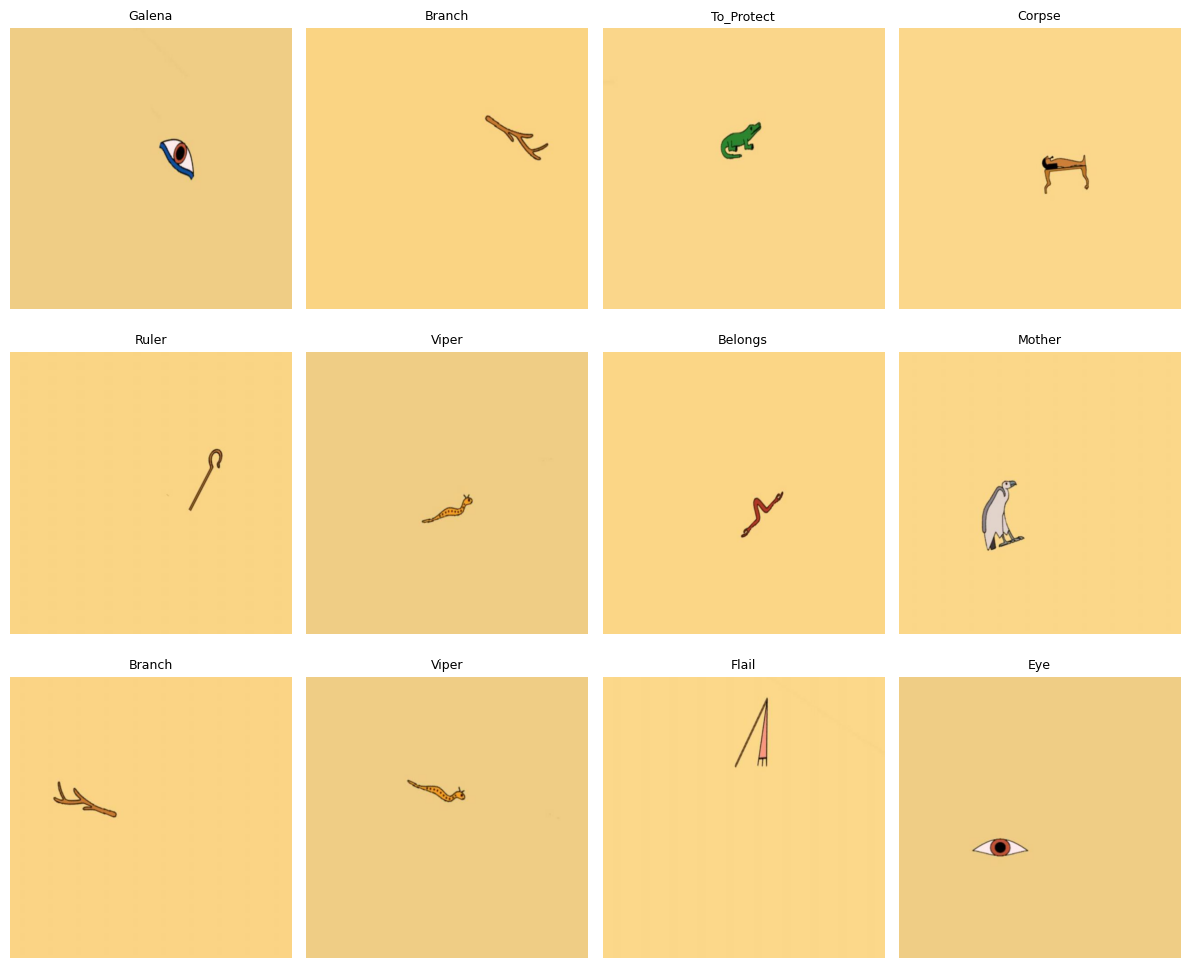

In [19]:
n_samples = 12

samples = df_train.sample(
    n=min(n_samples, len(df_train)),
    random_state=SEED
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):
    image_path = Path(data_dirs['train']) / row["filename"]

    img = mpimg.imread(image_path)
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(str(row["class"]), fontsize=9)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Inspekcja wizualna wykazała, że część obrazów zawiera duże obszary tła w stosunku do właściwego hieroglifu. Może to ograniczać efektywne wykorzystanie rozdzielczości wejściowej modelu oraz zwiększać koszt przetwarzania obrazów. W związku z tym, w kolejnych zadaniach zastosowane zostanie przycinanie nadmiarowego tła, tak aby hieroglif zajmował większą część obrazu przy zachowaniu jego istotnych cech.